Statistical Hypothesis Testing & Turnover Drivers
### Testing the significance of Overtime, Compensation, and Tenure on Employee Attrition

In [5]:
import pandas as pd
import numpy as np
from scipy import stats
# Load our saved clean data
df = pd.read_csv(r'C:\Users\ar628\Downloads\Coding\Employee Attrition & Retention Diagnostic\data\processed\data\employee_attrition_cleaned.csv')
print(f"Loaded {df.shape[0]} rows and {df.shape[1]} columns successfully!")

Loaded 1470 rows and 33 columns successfully!


Chi-Square Test (Overtime vs. Quitting)

It checks if working overtime and quitting are linked together, or if it's just random coincidence.

In [6]:
import pandas as pd
from scipy import stats

# 1. Count how many people quit vs stayed in both Overtime groups
contingency_table = pd.crosstab(df['OverTime'], df['Attrition'])
print("--- Overtime vs Attrition Table ---")
print(contingency_table)

# 2. Run the Chi-Square test
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)

print("\n--- Chi-Square Test Results ---")
print(f"Chi-Square Score: {chi2:.2f}")
print(f"p-value:          {p_value:.4e}")

# If p-value is smaller than 0.05, it means the connection is 100% real
if p_value < 0.05:
    print("\n Result: Statistically Significant!")
    print("Working overtime is definitely connected to employees quitting.")
else:
    print("\n Result: No real connection found.")

--- Overtime vs Attrition Table ---
Attrition   No  Yes
OverTime           
No         944  110
Yes        289  127

--- Chi-Square Test Results ---
Chi-Square Score: 87.56
p-value:          8.1584e-21

 Result: Statistically Significant!
Working overtime is definitely connected to employees quitting.


Two-Sample T-Test (Monthly Income)

It checks if employees who quit were paid significantly less than those who stayed.


In [7]:
# 1. Separate the salaries of people who stayed vs people who left
salary_stayed = df[df['Attrition'] == 'No']['MonthlyIncome']
salary_left = df[df['Attrition'] == 'Yes']['MonthlyIncome']

# Compare the average pay of both groups
print(f"Average pay for people who STAYED: ${salary_stayed.mean():,.2f}")
print(f"Average pay for people who LEFT:   ${salary_left.mean():,.2f}")
print(f"Pay Gap:                           ${salary_stayed.mean() - salary_left.mean():,.2f}")

# 2. Run the T-Test to see if this salary difference is statistically real
t_stat, p_val = stats.ttest_ind(salary_stayed, salary_left)

print("\n--- T-Test Results ---")
print(f"T-statistic: {t_stat:.2f}")
print(f"p-value:     {p_val:.4e}")

# If p-value < 0.05, the salary gap is real, not just a fluke
if p_val < 0.05:
    print("\n Result: Statistically Significant!")
    print("Employees who quit were indeed earning significantly lower pay.")
else:
    print("\n Result: No significant pay difference.")

Average pay for people who STAYED: $6,832.74
Average pay for people who LEFT:   $4,787.09
Pay Gap:                           $2,045.65

--- T-Test Results ---
T-statistic: 6.20
p-value:     7.1474e-10

 Result: Statistically Significant!
Employees who quit were indeed earning significantly lower pay.


Scale Data & Fit Logistic Regression

It trains a simple model to compare all factors (overtime, salary, satisfaction, years) on an equal playing field.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Choose the factors we want to test
features = [
    'OverTime',
    'MonthlyIncome',
    'TotalWorkingYears',
    'YearsAtCompany',
    'YearsSinceLastPromotion',
    'JobSatisfaction',
    'WorkLifeBalance'
]

X = df[features]
y = df['Attrition']
X['OverTime'] = X['OverTime'].map({'Yes': 1, 'No': 0})
# Balance all numbers so large salaries don't overpower small ratings
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train the simple model
model = LogisticRegression(random_state=42)
model.fit(X_scaled, y)

print(" Model trained successfully and ready for analysis!")



 Model trained successfully and ready for analysis!


C:\Users\ar628\AppData\Local\Temp\ipykernel_2792\2345122931.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['OverTime'] = X['OverTime'].map({'Yes': 1, 'No': 0})


Calculate & Rank Risk Multipliers (Odds Ratios)

It turns the model's math into a simple "Risk Multiplier" (Odds Ratio) to rank which factors push people to quit the most.

In [12]:
# Convert model math into easy-to-read risk scores (Odds Ratios)
# Above 1.0 = Increases chance of quitting
# Below 1.0 = Protects and makes employees stay
risk_table = pd.DataFrame({
    'Factor': features,
    'Risk_Multiplier': np.exp(model.coef_[0])
}).sort_values(by='Risk_Multiplier', ascending=False).reset_index(drop=True)

# Round numbers to 2 decimal places so they look clean
risk_table['Risk_Multiplier'] = risk_table['Risk_Multiplier'].round(2)

print("--- Ranking Factors: Highest to Lowest Risk ---")
print(risk_table)

--- Ranking Factors: Highest to Lowest Risk ---
                    Factor  Risk_Multiplier
0                 OverTime             1.91
1  YearsSinceLastPromotion             1.44
2          WorkLifeBalance             0.84
3            MonthlyIncome             0.75
4          JobSatisfaction             0.71
5           YearsAtCompany             0.68
6        TotalWorkingYears             0.67


OverTime (1.91): Nearly doubles the odds of quitting!

  
YearsSinceLastPromotion (1.44): Waiting for a promotion increases quitting risk by 44%!

  
All the others are 
<1.0, which means good salary, high job satisfaction, and more years at the company actually protect employees from quitting!

**Plot & Save the Turnover Risk Chart**

It draws a color-coded bar chart showing these risk multipliers, making the results instantly understandable at a glance.

C:\Users\ar628\AppData\Local\Temp\ipykernel_2792\1787616047.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


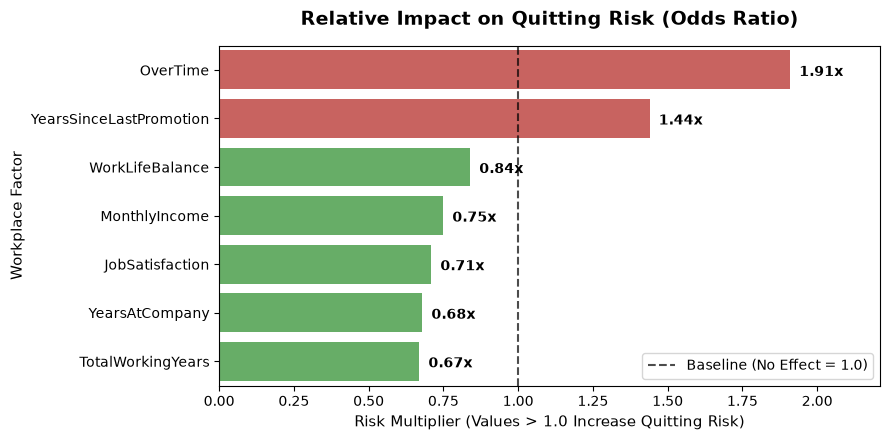

 Chart saved to images/06_turnover_drivers_odds_ratio.png!


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 4.5))

# Red bars = Increases risk (> 1.0)
# Green bars = Protects against quitting (< 1.0)
colors = ['#d9534f' if score > 1.0 else '#5cb85c' for score in risk_table['Risk_Multiplier']]

# Create the horizontal bar plot
ax = sns.barplot(
    data=risk_table,
    x='Risk_Multiplier',
    y='Factor',
    palette=colors
)

# Draw a dotted line at 1.0 (the neutral baseline)
plt.axvline(x=1.0, color='black', linestyle='--', alpha=0.7, label='Baseline (No Effect = 1.0)')

plt.title('Relative Impact on Quitting Risk (Odds Ratio)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Risk Multiplier (Values > 1.0 Increase Quitting Risk)', fontsize=11)
plt.ylabel('Workplace Factor', fontsize=11)
plt.legend(loc='lower right')

# Add the number labels next to each bar
for p in ax.patches:
    val = p.get_width()
    ax.annotate(f"{val:.2f}x", 
                (val + 0.03, p.get_y() + 0.45), 
                va='center', fontsize=10, fontweight='bold')

plt.xlim(0, max(risk_table['Risk_Multiplier']) + 0.3)
plt.tight_layout()

# Save the final chart into your images folder for GitHub
plt.savefig(r'C:\Users\ar628\Downloads\Coding\Employee Attrition & Retention Diagnostic\images\06_turnover_drivers_odds_ratio.png', dpi=300)
plt.show()

print(" Chart saved to images/06_turnover_drivers_odds_ratio.png!")